# M10 概覽 | 自訂後端：把硬體約束寫成 Quantizer

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m10_custom_backend/00_overview.ipynb)

M08、M09 的後端都很寬鬆：per-channel、非對稱 activation、任意 scale、動態 batch 都吃，沒有 int8 版本的 op 就留在 fp32。VPU／NPU 類的硬體通常窄得多（[M09 概覽](../m09_onnx_runtime/00_overview.ipynb)〈CPU 與 VPU／NPU 的差別〉）。

這一章換到後端作者那一側：虛構一顆 VPU，做後端要交出去的三件事。

| 後端作者要做的 | 這一章的做法 | notebook |
|---|---|---|
| 給演算法人員一個 Quantizer | 把八條硬體約束寫成 `MyVPUQuantizer` | M10-1 |
| 吃圖之前先檢查 | 只讀 Q/DQ 圖的檢查 pass `check_vpu` | M10-2 |
| 不支援的 op 切回 CPU | 極簡的 partitioner `partition`，印出分區圖 | M10-3 |

後端本體在 [`vpu_quantizer.py`](vpu_quantizer.py)：本專案的檔案，不是 torchao 的 API，也不是 notebook。M10 的 notebook 用 `from vpu_quantizer import …` 匯入。VPU 是虛構的；約束是這類硬體常見的要求（一般說法），本專案沒有實機。

In [1]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m10_custom_backend")

In [2]:
#| echo: false
import torch

from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.data import calibration_batches
from common.models import example_inputs, get_model
from common.viz import draw
from vpu_quantizer import MyVPUQuantizer

quiet()
_ = torch.manual_seed(0)

## 先看一個例子：同一個 conv + relu，兩個後端的 Q/DQ 圖

最小的 conv + relu，分別用 `MyVPUQuantizer` 與 torchao 測試版 XNNPACKQuantizer 做 PTQ。VPU 只吃 static shape，所以兩邊都用 `export_module(..., dynamic_batch=False)`，校準資料的 batch 也和匯出時相同：

In [3]:
def ptq(quantizer):
    model, x = get_model("conv_relu").eval(), example_inputs(16)
    prepared = prepare_pt2e(export_module(model, x, dynamic_batch=False), quantizer)
    with torch.no_grad():
        for batch in calibration_batches(64, batch_size=16):
            prepared(*batch)
    return convert_pt2e(prepared)


vpu = ptq(MyVPUQuantizer())
xnn = ptq(get_xnnpack_quantizer(is_per_channel=True)[0])

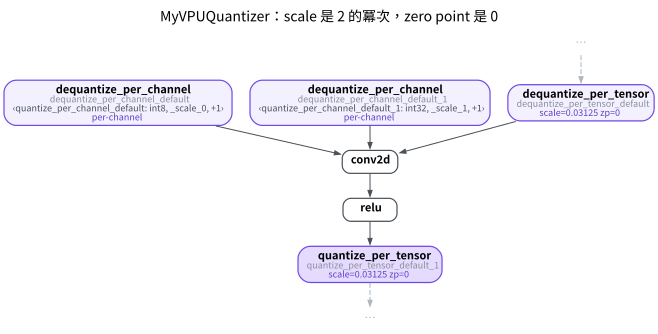

In [4]:
#| echo: false
draw(vpu, focus=["conv2d", "relu"], hops=1, title="MyVPUQuantizer：scale 是 2 的冪次，zero point 是 0")

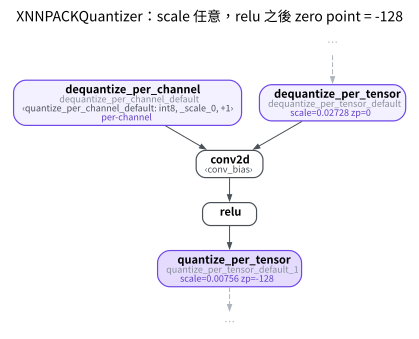

In [5]:
#| echo: false
draw(xnn, focus=["conv2d", "relu"], hops=1, title="XNNPACKQuantizer：scale 任意，relu 之後 zero point = -128")

兩張圖都是 conv+relu 一個單元，差在兩處：q/dq 上的數字，以及 conv2d 的 bias 有沒有 dq。先確認 q/dq 上的數字：

In [6]:
def qparams(gm):
    return [(float(n.args[1]), int(n.args[2])) for n in gm.graph.nodes
            if n.target == torch.ops.quantized_decomposed.quantize_per_tensor.default]


def is_pow2(s):
    return float(torch.log2(torch.tensor(s))).is_integer()


print("VPU 的 quantize_per_tensor (scale, zp)：", qparams(vpu))
print("XNNPACK 的 quantize_per_tensor (scale, zp)：", [(round(s, 5), z) for s, z in qparams(xnn)])
assert all(is_pow2(s) and z == 0 for s, z in qparams(vpu))
assert not all(is_pow2(s) for s, _ in qparams(xnn)) and qparams(xnn)[-1][1] == -128

VPU 的 quantize_per_tensor (scale, zp)： [(0.03125, 0), (0.03125, 0)]
XNNPACK 的 quantize_per_tensor (scale, zp)： [(0.02728, 0), (0.00756, -128)]


再看 bias：VPU 圖上的 conv2d 多一個 dq 輸入，來自約束 (5)。`bias_spec()` 用 `DerivedQuantizationSpec`，從輸入 activation 與 weight 的 observer 推出 bias 的 scale（$s_{in} \cdot s_w$，每個 output channel 一個），`convert_pt2e` 就把 bias 存成 int32 常數、後面接一個 dq。torchao 測試版 XNNPACKQuantizer 不替 bias 貼標籤，bias 留在 fp32；XNNPACK 在 lowering 時才把它量化成 int32（M08-2 A 印出的 `qcint32`）。

In [7]:
def conv_node(gm):
    return next(n for n in gm.graph.nodes if n.target == torch.ops.aten.conv2d.default)


c_vpu, c_xnn = conv_node(vpu), conv_node(xnn)
dq_x, dq_w, dq_b = c_vpu.args[:3]
b_vpu = getattr(vpu, dq_b.args[0].target)
b_xnn = xnn.get_parameter(c_xnn.args[2].target)
print(f"VPU：conv2d 的 bias 是 {b_vpu.dtype} 常數，經過 {dq_b.target}")
print(f"XNNPACK：conv2d 的 bias 是 {b_xnn.dtype} 參數（{c_xnn.args[2].op}），沒有 dq")
assert dq_b.target == torch.ops.quantized_decomposed.dequantize_per_channel.default and b_vpu.dtype == torch.int32
assert torch.equal(getattr(vpu, dq_b.args[1].target), dq_x.args[1] * getattr(vpu, dq_w.args[1].target))  # s_in·s_w
assert c_xnn.args[2].op == "get_attr" and b_xnn.dtype == torch.float32

VPU：conv2d 的 bias 是 torch.int32 常數，經過 quantized_decomposed.dequantize_per_channel.default
XNNPACK：conv2d 的 bias 是 torch.float32 參數（get_attr），沒有 dq


XNNPACK 的圖在 CPU 上完全合理，但放不上這顆 VPU：它要的 scale 是 $2^k$、zero point 是 0。這些要求要在**量化之前**就交給演算法人員，寫成一個 Quantizer。

## 八條約束與 PT2E 的機制

| VPU 約束 | PT2E 做法 | `vpu_quantizer.py` 裡的位置 |
|---|---|---|
| (1) 只有 `VPU_OPS` 有 kernel | 其餘 op 不貼標籤 → 留在 fp32 | `VPU_OPS`、`annotate()` 的最後 |
| (2) activation per-tensor symmetric | `qscheme=per_tensor_symmetric` | `act_spec()` |
| (3) weight per-channel symmetric | `qscheme=per_channel_symmetric` | `weight_spec()` |
| (4) scale 是 2 的冪次 | 繼承 observer，覆寫 `calculate_qparams()` | `Pow2MinMaxObserver` 等 |
| (5) bias int32、scale = $s_{in} \cdot s_w$ | `DerivedQuantizationSpec` | `bias_spec()` |
| (6) add／cat／pool 等輸入輸出同 scale | `SharedQuantizationSpec` | `_add()`、`_cat()`、`_same_scale()` |
| (7) conv／add + relu 融合 | 輸出標籤貼在 relu，中間不標 | `fused_relu()` |
| (8) 只吃 static shape | `validate()` 看到 SymInt 就報錯 | `validate()` |

這一章接上 M03 預留的三個伏筆：`validate()`（M03-3）、int32 bias 的 `DerivedQuantizationSpec`（M03-5）、沒標籤的 op 留在 fp32（M03-6）。

## 硬體為什麼要這些約束

| 約束 | 硬體省掉了什麼 |
|---|---|
| zero point = 0 | 整數 conv 的交叉項（見下） |
| scale = $2^k$ | requant 的乘法器，只剩 shift（M10-2 C） |
| 輸入輸出同 scale | add／pool 前後的 requant |
| static shape | 執行時的記憶體配置（編譯時就排好，同 M08-2 C） |

符號沿用 [M01 概覽](../m01_hello_pt2e/00_overview.ipynb)〈affine 量化：scale 與 zero point〉：整數 $q$ 代表的實數是 $s\,(q - z)$，$s$ 是 scale、$z$ 是 zero point。下標 $x$ 指 conv 的輸入 activation（$s_x$ 就是約束 (5) 的 $s_{in}$），下標 $w$ 指 weight。

conv 的一個輸出位置是 kernel 視窗裡（輸入 channel × kernel 高 × 寬）的乘積和 $\sum x\,w$。把 $x$、$w$ 換成整數表示：

$$
\sum x\,w \approx \sum s_x (q_x - z_x) \cdot s_w (q_w - z_w) = s_x s_w \sum (q_x - z_x)(q_w - z_w)
$$

$s_x$ 是 per-tensor、$s_w$ 在同一個輸出 channel 內只有一個值，所以 $s_x s_w$ 可以提到總和外面，留給 requant。整數 kernel 要算的是剩下的總和，展開後是：

$$
\sum (q_x - z_x)(q_w - z_w) = \sum q_x q_w - z_w \sum q_x - z_x \sum q_w + z_x z_w \sum 1 \tag{1}
$$

第一項是純整數的乘加；含 $z$ 的其餘三項就是表中說的**交叉項**：

- $z_w = 0$ 時，含 $\sum q_x$ 的項消失。$q_x$ 是輸入，每個輸出位置都不同，這一項要在推論時逐位置累加，省不掉，只能靠 $z_w = 0$ 讓它變成 0；常數項 $z_x z_w \sum 1$ 也跟著是 0。常見的 weight 是 per-channel symmetric，就是這個設定。
- 剩下的 $z_x \sum q_w$：activation 是 per-tensor、$z_x$ 在校準時定死，和 $q_w$ 都是常數，可以事先折進 bias。

用隨機整數驗證式 (1)，一個輸出位置、27 個乘積（3×3×3 的 conv）：

In [8]:
g = torch.Generator().manual_seed(0)
q_x = torch.randint(-128, 128, (27,), generator=g, dtype=torch.int64)
q_w = torch.randint(-127, 128, (27,), generator=g, dtype=torch.int64)
z_x, z_w = 5, 3
direct = ((q_x - z_x) * (q_w - z_w)).sum()
expanded = (q_x * q_w).sum() - z_w * q_x.sum() - z_x * q_w.sum() + z_x * z_w * len(q_x)
print(f"直接算 {int(direct)}，展開式 {int(expanded)}")
assert direct == expanded

直接算 -20196，展開式 -20196


## 流程

```text
vpu_quantizer.py      把硬體約束寫成標籤（MyVPUQuantizer）
  → prepare_pt2e      annotate() 貼標籤，validate() 擋下做不到的圖
  → 校準、convert     Pow2 observer 決定 Q/DQ 圖上的 scale
  → check_vpu()       後端：只讀 Q/DQ 圖，檢查約束（M10-2）
  → partition()       後端：清單外的 op 切回 CPU（M10-3）
```

前三步是演算法人員用後端給的 Quantizer 做的事；後兩步是後端拿到 Q/DQ 圖之後自己做的事。中間交接的只有 Q/DQ 圖，所以後端不能只信 quantizer 的承諾：M10-2 拿 XNNPACK 的圖過同一個檢查，違反了七條規則裡的五條。

## 小結與本章地圖

- 後端 Quantizer 就是把硬體約束翻譯成標籤：`qscheme`、自訂 observer、Shared／Derived、「不標」、`validate()`，各管一類約束。
- 2 的冪次 scale 往上取，不多 clip，但解析度最多粗 2 倍；換到的是 requant 只要右移。
- 後端拿到的只有 Q/DQ 圖，要自己檢查、自己切圖。op 清單決定圖被切成幾段。

| notebook | 回答的問題 |
|---|---|
| [M10-1 MyVPUQuantizer](01_vpu_quantizer.ipynb) | 八條約束怎麼寫成標籤；pow2 observer 的代價；`validate()`；哪些 tensor 被迫同 scale |
| [M10-2 檢查 pass](02_constraint_checker.ipynb) | Q/DQ 圖合不合規；XNNPACK 的圖違反哪些規則；requant 的右移位數 |
| [M10-3 Fallback 報告](03_fallback_report.ipynb) | 哪些 op 切回 CPU；子圖、邊界與搬移量 |

這一章刻意跳過的：

- 每條約束各掉多少精度（M10-1 只印一行 SQNR 當 sanity check）。
- 整數模擬：M10-2 只算出右移位數，沒有用整數實作 conv 和 Q/DQ 圖比對；bit exact 與否和後端實作強相關（M08 概覽〈和 Q/DQ 圖的數值差異〉）。
- 單一 op 的子圖划不划算：要實機量測，本專案沒有。

M10 是學習路徑的最後一章。回到[首頁](../index.qmd)看全貌，或回到 [M07 概覽](../m07_representation_lowering/00_overview.ipynb)看三條路線怎麼接到這裡。

## 參考資料

- PyTorch 官方教學：[How to Write a Quantizer for PyTorch 2 Export Quantization](https://docs.pytorch.org/ao/stable/pt2e_quantization/pt2e_quantizer.html)
- [RFC-0019：Extending PyTorch Quantization to Custom Backends](https://github.com/pytorch/rfcs/blob/master/RFC-0019-Extending-PyTorch-Quantization-to-Custom-Backends.md)
- 量化白皮書：R. Krishnamoorthi, [Quantizing deep convolutional networks for efficient inference: A whitepaper](https://arxiv.org/abs/1806.08342)（整數 conv 的展開式與 zero point）